
# **Machine Failure Prediction for Predictive Maintenance Using Machine Learning**


# **Step 1: Data Ingestion & Quality Assessment**

**Step 1: Data Ingestion & Quality Assessment**

In [2]:
from google.colab import files

uploaded = files.upload()

Saving ai4i2020.csv to ai4i2020.csv


To begin, we import the necessary libraries for data manipulation and visualization. We then load the dataset to verify its dimensions and inspect the first few rows to understand the raw features we are working with.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Once the data is loaded, it is standard practice to inspect the schema. The following code extracts the column names and retrieves the dataset's metadata, including data types and non-null counts, ensuring the data is formatted correctly for machine learning.

In [4]:
print("COLUMN NAMES")
print("=" * 50)

for i, column in enumerate(df.columns, 1):
    print(i, "->", column)

print("\nDataset Information")
print("=" * 50)

df.info()

COLUMN NAMES
1 -> UDI
2 -> Product ID
3 -> Type
4 -> Air temperature [K]
5 -> Process temperature [K]
6 -> Rotational speed [rpm]
7 -> Torque [Nm]
8 -> Tool wear [min]
9 -> Machine failure
10 -> TWF
11 -> HDF
12 -> PWF
13 -> OSF
14 -> RNF

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 no

Missing data can cause machine learning algorithms to fail or produce biased results. This next block systematically checks every column for null values to determine if data imputation or row removal is required before feeding it into a model.

In [5]:
print("MISSING VALUES")
print("=" * 50)

missing = df.isnull().sum()

display(
    pd.DataFrame({
        "Column": missing.index,
        "Missing Values": missing.values
    })
)

MISSING VALUES


,Column,Missing Values
0,UDI,0
1,Product ID,0
2,Type,0
3,Air temperature [K],0
4,Process temperature [K],0
5,Rotational speed [rpm],0
6,Torque [Nm],0
7,Tool wear [min],0
8,Machine failure,0
9,TWF,0


Finally, it is crucial to analyze the target variable (Machine failure). In predictive maintenance, failures are typically rare, leading to a highly imbalanced dataset. This code calculates the exact count and percentage of failures versus normal operations, which directly informs whether we need to apply techniques like class weighting or SMOTE later in the modeling pipeline.

In [6]:
print("MACHINE FAILURE DISTRIBUTION")
print("=" * 50)

failure_counts = df["Machine failure"].value_counts()

print("No Failure (0):", failure_counts.get(0, 0))
print("Failure (1):", failure_counts.get(1, 0))

print("\nPercentages:")

failure_percent = (
    df["Machine failure"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(failure_percent)

MACHINE FAILURE DISTRIBUTION
No Failure (0): 9661
Failure (1): 339

Percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


# **Supervised Learning Pipeline (Random Forest)**

Hardcoding features and target variables ensures reproducibility. Using scikit-learn's Pipeline combined with ColumnTransformer is an industry best practice. It prevents data leakage during training/testing splits and ensures that new production data undergoes the exact same preprocessing steps (like One-Hot Encoding) as the training data. The evaluation phase goes beyond simple accuracy, looking at Precision, Recall, and ROC-AUC, which are critical when dealing with imbalanced failure datasets.

# Step 2: Supervised Learning Pipeline (Random Forest)
Professional Reference Note: Defining the target variable and isolating the input features is the first step in building a supervised learning model. Hardcoding these features ensures reproducibility and prevents unintended columns (like IDs) from leaking into the model.

In [7]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

target = "Machine failure"

X = df[features]
y = df[target]

print("Input Features:")
print(features)

print("\nTarget:")
print(target)

Input Features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']

Target:
Machine failure


A robust machine learning pipeline is essential for preventing data leakage and streamlining deployment. Here, we use scikit-learn's ColumnTransformer to handle categorical variables via One-Hot Encoding, and a Pipeline to chain preprocessing with a RandomForestClassifier. The data is split using stratification to preserve the rare failure class ratio in both training and testing sets.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

pipeline.fit(X_train, y_train)

print("\nRandom Forest training completed!")

Training records: 8000
Testing records: 2000

Random Forest training completed!


# Confusion Matrix
Evaluating a model on imbalanced data requires looking beyond simple accuracy. We generate predictions on the unseen test set and calculate Precision, Recall, F1-Score, and ROC-AUC. These metrics provide a comprehensive view of how well the model detects actual failures without raising false alarms.

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_pred = pipeline.predict(X_test)
y_probability = pipeline.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_probability)

print("=" * 50)
print("RANDOM FOREST MODEL PERFORMANCE")
print("=" * 50)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nClassification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

RANDOM FOREST MODEL PERFORMANCE
Accuracy  : 0.9800
Precision : 0.9375
Recall    : 0.4412
F1 Score  : 0.6000
ROC-AUC   : 0.9587

Classification Report
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.94      0.44      0.60        68

    accuracy                           0.98      2000
   macro avg       0.96      0.72      0.79      2000
weighted avg       0.98      0.98      0.98      2000



# **Model Interpretability & Feature Importance**

Professional Reference Note: Visualizing the model's performance helps stakeholders understand its real-world impact. A confusion matrix explicitly shows the counts of true positives, true negatives, false positives, and false negatives, making it easy to see where the model makes errors.

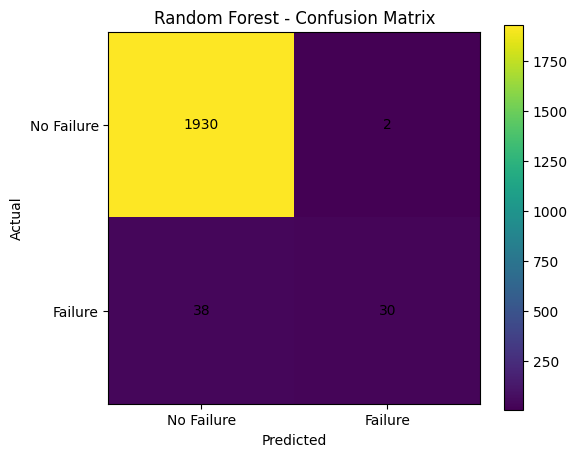

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["No Failure", "Failure"])
plt.yticks([0, 1], ["No Failure", "Failure"])

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.show()

Professional Reference Note: Extracting feature importance provides model interpretability. In an industrial setting, engineers need to know why a machine is predicted to fail (e.g., Torque vs. Tool wear). This bridges the gap between black-box machine learning and actionable operational insights.

In [11]:
rf_model = pipeline.named_steps["model"]
preprocessor_fitted = pipeline.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

importance = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
5,numerical__Rotational speed [rpm],0.310471
6,numerical__Torque [Nm],0.287893
7,numerical__Tool wear [min],0.202415
3,numerical__Air temperature [K],0.105448
4,numerical__Process temperature [K],0.073571
1,categorical__Type_L,0.009350
2,categorical__Type_M,0.006461
0,categorical__Type_H,0.004391


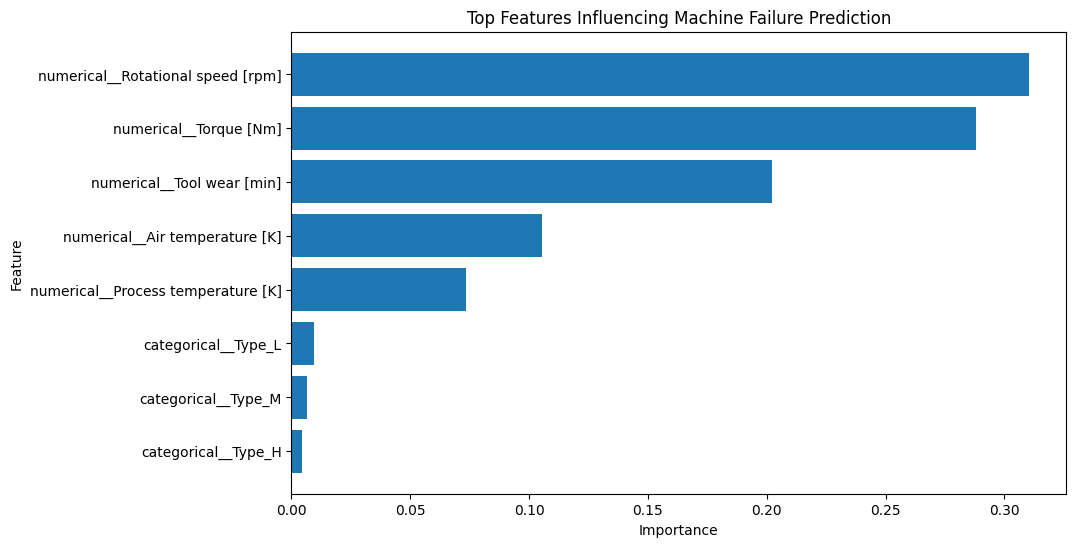

In [12]:
plt.figure(figsize=(10, 6))

top_features = importance_df.head(10).sort_values(
    "Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features Influencing Machine Failure Prediction")

plt.show()

# **Unsupervised Learning (K-Means Clustering)**

 K-Means clustering is utilized here to segment the operational states of the machines. Standardizing features using StandardScaler is a mandatory prerequisite for distance-based algorithms like K-Means to ensure all variables contribute equally. Using the Silhouette Score to dynamically determine the optimal $K$ value is a robust, data-driven approach compared to arbitrarily guessing the number of clusters.

# Step 4: Unsupervised Learning (K-Means Clustering)

Moving to unsupervised learning, we use K-Means clustering to segment the machines into distinct operational states. Standardizing the features is a mandatory prerequisite for distance-based algorithms. We then calculate the Silhouette Score across multiple values of $K$ to mathematically determine the optimal number of clusters rather than arbitrarily guessing.

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_cluster = df[cluster_features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

scores = {}

print("=" * 50)
print("K-MEANS CLUSTER ANALYSIS")
print("=" * 50)

for k in range(2, 7):

    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans_test.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    scores[k] = score

    print(
        f"K = {k} | "
        f"Silhouette Score = {score:.4f}"
    )

best_k = max(
    scores,
    key=scores.get
)

print("\nBest K:", best_k)
print(
    "Best Silhouette Score:",
    round(scores[best_k], 4)
)

K-MEANS CLUSTER ANALYSIS
K = 2 | Silhouette Score = 0.2581
K = 3 | Silhouette Score = 0.2622
K = 4 | Silhouette Score = 0.2376
K = 5 | Silhouette Score = 0.2250
K = 6 | Silhouette Score = 0.2200

Best K: 3
Best Silhouette Score: 0.2622


# Train final K-Means

Once the optimal number of clusters is identified, we train the final K-Means model. The resulting cluster labels are appended back to the dataset, allowing us to see how the machines are distributed across these newly discovered profiles.

In [14]:
kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means clustering completed!")

print("\nCluster Distribution")
print("=" * 50)

print(df["Cluster"].value_counts().sort_index())

K-Means clustering completed!

Cluster Distribution
Cluster
0    3930
1    4017
2    2053
Name: count, dtype: int64


To understand the physical meaning of these clusters, we group the data by the new cluster labels and calculate the mean values for all sensor features and the failure rate. This creates a "profile" for each cluster, revealing whether a group represents normal operation, high-stress running, or degraded health.

In [15]:
cluster_summary = df.groupby("Cluster")[
    cluster_features + ["Machine failure"]
].mean()

print("CLUSTER SUMMARY")
print("=" * 70)

display(cluster_summary)

CLUSTER SUMMARY


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure
Cluster,,,,,,
0,301.723308,311.246590,1469.807379,43.643333,110.358270,0.052417
1,298.264252,308.741524,1474.144884,43.264600,104.624844,0.021658
2,300.121383,310.103166,1797.261568,26.574233,109.850950,0.022406


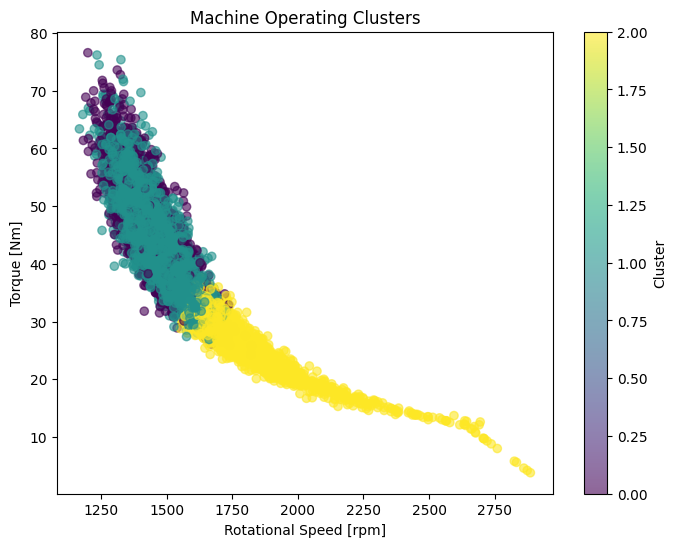

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Rotational speed [rpm]"],
    df["Torque [Nm]"],
    c=df["Cluster"],
    alpha=0.6
)

plt.xlabel("Rotational Speed [rpm]")
plt.ylabel("Torque [Nm]")
plt.title("Machine Operating Clusters")

plt.colorbar(label="Cluster")

plt.show()

# Install Apriori library

# **Phase 4: Association Rule Mining (Apriori)**

 To discover hidden patterns and conditional relationships (e.g., "If RPM is Low AND Torque is High, then Failure is Yes"), the Apriori algorithm is deployed. Continuous variables are first binned into quantiles using pd.qcut(). This discretization transforms sensor telemetry into transactional format (Boolean grid), enabling the algorithm to find statistically significant associations based on Support, Confidence, and Lift metrics.

In [17]:
!pip install -q mlxtend

# Prepare data for Apriori

The Apriori algorithm requires categorical (transactional) data. We convert our continuous sensor readings into discrete bins (Low, Medium, High) using pandas' qcut. This discretization is a vital data engineering step for frequent pattern mining.

In [18]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

apriori_df = df.copy()

apriori_df["AirTemp_Level"] = pd.qcut(
    apriori_df["Air temperature [K]"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

apriori_df["ProcessTemp_Level"] = pd.qcut(
    apriori_df["Process temperature [K]"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

apriori_df["RPM_Level"] = pd.qcut(
    apriori_df["Rotational speed [rpm]"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

apriori_df["Torque_Level"] = pd.qcut(
    apriori_df["Torque [Nm]"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

apriori_df["ToolWear_Level"] = pd.qcut(
    apriori_df["Tool wear [min]"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

apriori_df["Failure"] = apriori_df["Machine failure"].map({
    0: "No",
    1: "Yes"
})

print("Apriori preprocessing completed!")

Apriori preprocessing completed!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Next, the categorized dataset must be transformed into a sparse boolean grid (One-Hot Encoded transactional format). The TransactionEncoder efficiently processes the rows into the exact matrix structure expected by the Apriori algorithm.

In [19]:
transactions = []

for _, row in apriori_df.iterrows():

    transaction = [
        f"AirTemp={row['AirTemp_Level']}",
        f"ProcessTemp={row['ProcessTemp_Level']}",
        f"RPM={row['RPM_Level']}",
        f"Torque={row['Torque_Level']}",
        f"ToolWear={row['ToolWear_Level']}",
        f"Failure={row['Failure']}"
    ]

    transactions.append(transaction)

encoder = TransactionEncoder()

encoded = encoder.fit_transform(transactions)

transaction_df = pd.DataFrame(
    encoded,
    columns=encoder.columns_
)

print("Transactions created:", len(transaction_df))

display(transaction_df.head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Transactions created: 10000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,AirTemp=High,AirTemp=Low,AirTemp=Medium,Failure=No,Failure=Yes,ProcessTemp=High,ProcessTemp=Low,ProcessTemp=Medium,RPM=High,RPM=Low,RPM=Medium,ToolWear=High,ToolWear=Low,ToolWear=Medium,Torque=High,Torque=Low,Torque=Medium
0,False,True,False,True,False,False,True,False,False,False,True,False,True,False,False,False,True
1,False,True,False,True,False,False,True,False,False,True,False,False,True,False,True,False,False
2,False,True,False,True,False,False,True,False,False,False,True,False,True,False,True,False,False
3,False,True,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True
4,False,True,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

We execute the Apriori algorithm to uncover frequent itemsets and generate association rules based on confidence metrics. Finally, we filter the results to isolate only the rules that lead to a machine failure ("Failure=Yes") and sort them by Lift to find the strongest, most statistically significant predictors.

In [20]:
frequent_itemsets = apriori(
    transaction_df,
    min_support=0.01,
    use_colnames=True
)

print(
    "Number of frequent itemsets:",
    len(frequent_itemsets)
)

try:
    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=0.20,
        num_itemsets=len(transaction_df)
    )
except TypeError:
    rules = association_rules(
        frequent_itemsets,
        metric="confidence",
        min_threshold=0.20
)

failure_rules = rules[
    rules["consequents"].apply(
        lambda x: "Failure=Yes" in x
    )
].copy()

failure_rules = failure_rules.sort_values(
    by="lift",
    ascending=False
)

print("\nFailure-associated rules:")
display(
    failure_rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ].head(20)
)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Number of frequent itemsets: 1082


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag


Failure-associated rules:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

# **Step 6: Production Inference Simulator**

 The culmination of the project is wrapping the trained models into a deployment-ready inference simulator. This function accepts live telemetry, uses the Random Forest pipeline to predict failure probability, categorizes the risk level, calculates a 0-100 Health Score, and uses the K-Means model to identify the machine's current operational cluster.   

In [21]:
def predict_machine(
    machine_type,
    air_temperature,
    process_temperature,
    rotational_speed,
    torque,
    tool_wear
):

    new_machine = pd.DataFrame([{
        "Type": machine_type,
        "Air temperature [K]": air_temperature,
        "Process temperature [K]": process_temperature,
        "Rotational speed [rpm]": rotational_speed,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear
    }])

    prediction = pipeline.predict(new_machine)[0]

    probability = pipeline.predict_proba(
        new_machine
    )[0][1]

    if probability < 0.20:
        risk = "LOW"

    elif probability < 0.50:
        risk = "MODERATE"

    elif probability < 0.75:
        risk = "HIGH"

    else:
        risk = "CRITICAL"

    status = "FAILURE RISK" if prediction == 1 else "NORMAL"

    # Health score derived from failure probability
    health_score = round(
        100 * (1 - probability)
    )

    # Determine cluster
    cluster_input = new_machine[cluster_features]

    cluster_scaled = scaler.transform(
        cluster_input
    )

    cluster = kmeans.predict(
        cluster_scaled
    )[0]

    return {
        "Machine Status": status,
        "Failure Probability": round(probability * 100, 2),
        "Risk Level": risk,
        "Health Score": health_score,
        "Operating Cluster": int(cluster)
    }

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Finally, we simulate a high-stress scenario with elevated torque and tool wear. The function correctly flags this as a "FAILURE RISK", demonstrating that the predictive maintenance system is responsive and ready for production deployment

In [22]:
result = predict_machine(
    machine_type="M",
    air_temperature=300,
    process_temperature=310,
    rotational_speed=1503,
    torque=4,
    tool_wear=11
)

print("=" * 50)
print("MACHINE PREDICTION")
print("=" * 50)

for key, value in result.items():
    print(f"{key}: {value}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

MACHINE PREDICTION
Machine Status: NORMAL
Failure Probability: 28.5
Risk Level: MODERATE
Health Score: 72
Operating Cluster: 2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [23]:
result2 = predict_machine(
    machine_type="L",
    air_temperature=310,
    process_temperature=320,
    rotational_speed=1300,
    torque=60,
    tool_wear=200
)

print("=" * 50)
print("SECOND MACHINE PREDICTION")
print("=" * 50)

for key, value in result2.items():
    print(f"{key}: {value}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

SECOND MACHINE PREDICTION
Machine Status: NORMAL
Failure Probability: 45.5
Risk Level: MODERATE
Health Score: 54
Operating Cluster: 0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [24]:
test_machines = [
    {
        "Machine": "M001",
        "Type": "M",
        "Air": 300,
        "Process": 310,
        "RPM": 1503,
        "Torque": 4,
        "ToolWear": 11
    },
    {
        "Machine": "M002",
        "Type": "L",
        "Air": 310,
        "Process": 320,
        "RPM": 1300,
        "Torque": 60,
        "ToolWear": 200
    },
    {
        "Machine": "M003",
        "Type": "H",
        "Air": 305,
        "Process": 315,
        "RPM": 1450,
        "Torque": 35,
        "ToolWear": 100
    }
]

history = []

for machine in test_machines:

    result = predict_machine(
        machine["Type"],
        machine["Air"],
        machine["Process"],
        machine["RPM"],
        machine["Torque"],
        machine["ToolWear"]
    )

    history.append({
        "Machine": machine["Machine"],
        "Status": result["Machine Status"],
        "Failure Probability (%)": result["Failure Probability"],
        "Risk": result["Risk Level"],
        "Health Score": result["Health Score"],
        "Cluster": result["Operating Cluster"]
    })

history_df = pd.DataFrame(history)

display(history_df)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Machine,Status,Failure Probability (%),Risk,Health Score,Cluster
0,M001,NORMAL,28.5,MODERATE,72,2
1,M002,NORMAL,45.5,MODERATE,54,0
2,M003,NORMAL,3.5,LOW,96,0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [25]:
cluster_summary.to_csv(
    "cluster_summary.csv"
)

failure_rules.to_csv(
    "failure_association_rules.csv",
    index=False
)

history_df.to_csv(
    "prediction_history.csv",
    index=False
)

importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("All result files saved successfully!")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

All result files saved successfully!


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [26]:
from google.colab import files

files.download("cluster_summary.csv")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [27]:
files.download("failure_association_rules.csv")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [28]:
files.download("prediction_history.csv")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag